temperature T = 3.472
same predictions before/after: True
before: mean confidence 0.779 | accuracy 0.509 | NLL 1.741 | ECE 0.271
after : mean confidence 0.501 | accuracy 0.509 | NLL 1.178 | ECE 0.047


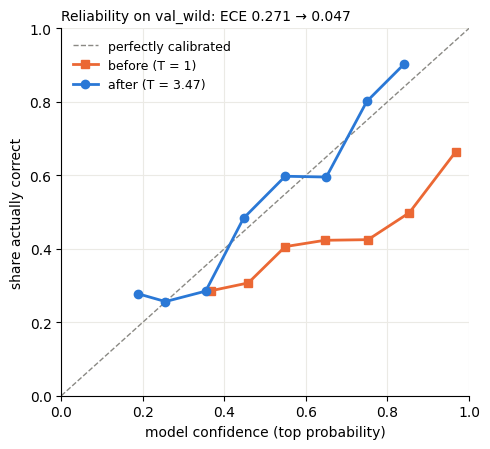

In [2]:
import json, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path
from plantdata import load_classes, read_manifest, PlantDataset, eval_transform, make_loader
from plantmodel import CropMaskedResNet
from calibration import collect_logits, fit_temperature, expected_calibration_error, reliability

SPLITS_DIR, CACHE_DIR = Path("splits_v2"), Path("cache_256")
CLASS_IDS, CROPS, crop_mask = load_classes(SPLITS_DIR)
manifest = read_manifest(CACHE_DIR)
device = "cuda"

ck = torch.load("checkpoints/R15.pt", map_location="cpu", weights_only=False)
model = CropMaskedResNet(ck["config"]["depth"], crop_mask, pretrained=False)
model.load_state_dict(ck["state_dict"])
model.to(device).eval()

val_wild_loader = make_loader(PlantDataset(manifest, "val_wild", CACHE_DIR, CROPS, eval_transform()),
                              batch_size=128, train=False, num_workers=0)
logits, labels = collect_logits(model, val_wild_loader, device)

T = fit_temperature(logits, labels)
before, after = logits.softmax(dim=1), (logits / T).softmax(dim=1)
print(f"temperature T = {T:.3f}")
print(f"same predictions before/after: {bool((before.argmax(1) == after.argmax(1)).all())}")
for name, p in [("before", before), ("after", after)]:
    nll = F.nll_loss(p.clamp_min(1e-12).log(), labels).item()
    print(f"{name:6s}: mean confidence {p.max(1).values.mean():.3f} | accuracy {(p.argmax(1) == labels).float().mean():.3f}"
          f" | NLL {nll:.3f} | ECE {expected_calibration_error(p, labels):.3f}")

Path("checkpoints/R15_calibration.json").write_text(json.dumps(
    {"run_id": "R15", "temperature": T, "fitted_on": "val_wild", "images": len(labels)}, indent=2))

fig, ax = plt.subplots(figsize=(5, 4.6))
ax.plot([0, 1], [0, 1], color="#8a8984", lw=1, ls="--", label="perfectly calibrated")
for name, p, colour, marker in [("before (T = 1)", before, "#eb6834", "s"), (f"after (T = {T:.2f})", after, "#2a78d6", "o")]:
    rows = [r for r in reliability(p, labels) if r[2] >= 20]     # skip bins with too few images
    ax.plot([r[0] for r in rows], [r[1] for r in rows], color=colour, marker=marker, ms=6, lw=2, label=name)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("model confidence (top probability)")
ax.set_ylabel("share actually correct")
ax.set_title(f"Reliability on val_wild: ECE {expected_calibration_error(before, labels):.3f} → "
             f"{expected_calibration_error(after, labels):.3f}", fontsize=10, loc="left")
ax.grid(color="#ebeae5", lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig("figures/q4_reliability.png", dpi=200)
plt.show()

out-of-scope PlantDoc images: 695  (squash_powdery_mildew 130, raspberry_healthy 119, blueberry_healthy 115, peach_healthy 111, strawberry_healthy 96, soybean_healthy 65, cherry_healthy 57, tomato_spider_mites 2)
           auroc  threshold  in_scope_kept  ood_missed
msp        0.427      0.231           0.95       0.971
max_logit  0.657      0.559           0.95       0.902
energy     0.672      1.096           0.95       0.881
chosen score: energy


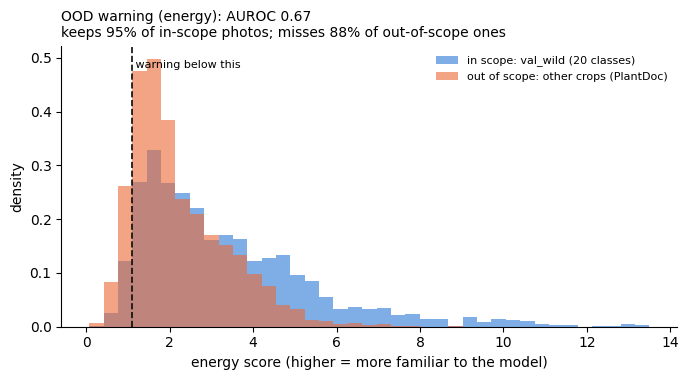

In [8]:
import numpy as np, pandas as pd
from ood import PathDataset, raw_logits, familiarity_scores, separation

T = json.loads(Path("checkpoints/R15_calibration.json").read_text())["temperature"]

# in-scope: val_wild (PlantDoc, the 20 classes), each image with its own crop
val_wild = PlantDataset(manifest, "val_wild", CACHE_DIR, CROPS, eval_transform())
raw_in = raw_logits(model, make_loader(val_wild, 128, train=False, num_workers=0), device)
s_in = familiarity_scores(raw_in, val_wild.crop_idx, crop_mask, T)

# out-of-scope: PlantDoc images of the EXCLUDED classes (other crops); never in train, val or test
excluded = [c["id"] for c in json.loads(Path("class_mapping.json").read_text())["classes"] if c["tier"] == "candidate"]
index = pd.read_csv("audit_outputs/image_index.csv")
ood_rows = index[(index["dataset"] == "plantdoc") & index["class_id"].isin(excluded)]
print(f"out-of-scope PlantDoc images: {len(ood_rows)}  ({', '.join(f'{k} {v}' for k, v in ood_rows['class_id'].value_counts().items())})")
ood_ds = PathDataset(ood_rows["path"], eval_transform())
raw_out = raw_logits(model, make_loader(ood_ds, 128, train=False, num_workers=4), device)
# the officer could select ANY crop for such a photo, so every OOD image is scored under all 6 crops
n = len(raw_out)
s_out = familiarity_scores(raw_out.repeat(len(CROPS), 1), torch.arange(len(CROPS)).repeat_interleave(n), crop_mask, T)

table = pd.DataFrame({name: separation(s_in[name], s_out[name]) for name in s_in}).T.round(3)
best = table["auroc"].idxmax()
print(table)
print(f"chosen score: {best}")

Path("checkpoints/R15_ood.json").write_text(json.dumps(
    {"run_id": "R15", "score": best, **{k: float(v) for k, v in table.loc[best].items()},
     "in_scope": "val_wild", "out_of_scope": f"PlantDoc excluded classes ({n} images x {len(CROPS)} crops)"}, indent=2))

fig, ax = plt.subplots(figsize=(7, 3.9))
bins = np.linspace(min(s_in[best].min(), s_out[best].min()), max(s_in[best].max(), s_out[best].max()), 40)
ax.hist(s_in[best].numpy(), bins=bins, density=True, alpha=0.6, color="#2a78d6", label="in scope: val_wild (20 classes)")
ax.hist(s_out[best].numpy(), bins=bins, density=True, alpha=0.6, color="#eb6834", label="out of scope: other crops (PlantDoc)")
ax.axvline(table.at[best, "threshold"], color="#0b0b0b", lw=1.2, ls="--")
ax.text(table.at[best, "threshold"], ax.get_ylim()[1] * 0.95, " warning below this", fontsize=8, va="top")
ax.set_xlabel(f"{best} score (higher = more familiar to the model)")
ax.set_ylabel("density")
ax.set_title(f"OOD warning ({best}): AUROC {table.at[best, 'auroc']:.2f}\nkeeps {table.at[best, 'in_scope_kept']:.0%} of "
             f"in-scope photos; misses {table.at[best, 'ood_missed']:.0%} of out-of-scope ones", fontsize=10, loc="left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("figures/q4_ood_scores.png", dpi=200)
plt.show()

In [7]:
import json, torch, pandas as pd
from pathlib import Path
from calibration import collect_logits
from plantdata import PlantDataset, eval_transform, make_loader

T = json.loads(Path("checkpoints/R15_calibration.json").read_text())["temperature"]
ck = torch.load("checkpoints/R15.pt", map_location="cpu", weights_only=False)
model = CropMaskedResNet(ck["config"]["depth"], crop_mask, pretrained=False)
model.load_state_dict(ck["state_dict"])
model.to(device).eval()

dataset = PlantDataset(manifest, "val_wild", CACHE_DIR, CROPS, eval_transform())
logits, labels = collect_logits(model, make_loader(dataset, batch_size=128, train=False, num_workers=0), device)
probs = (logits / T).softmax(dim=1)
top2 = probs.topk(2, dim=1).values
crop_idx = torch.tensor([CROPS.index(c) for c in dataset.info["crop"]])

table = pd.DataFrame({
    "classes_in_crop": crop_mask[crop_idx].sum(dim=1).numpy(),
    "top": top2[:, 0].numpy(),
    "margin": (top2[:, 0] - top2[:, 1]).numpy(),
    "correct": (probs.argmax(dim=1) == labels).numpy(),
})
table["crop_type"] = table.classes_in_crop.map(lambda n: "2-class crops" if n == 2 else "3+ class crops")
table["old_rule"] = table.top < 0.50
table["new_rule"] = (table.top < 0.50) | (table.margin < 0.20)

rows = []
for (crop_type, rule), part in [((ct, r), g) for ct, g in table.groupby("crop_type") for r in ("old_rule", "new_rule")]:
    warned = part[part[rule]]
    rows.append({"crops": crop_type, "rule": rule, "images": len(part), "warned": f"{len(warned) / len(part):.0%}",
                 "accuracy warned": round(warned.correct.mean(), 3) if len(warned) else None,
                 "accuracy not warned": round(part[~part[rule]].correct.mean(), 3)})
print(pd.DataFrame(rows).to_string(index=False))

         crops     rule  images warned  accuracy warned  accuracy not warned
 2-class crops old_rule     412     0%              NaN                0.716
 2-class crops new_rule     412    26%            0.604                0.755
3+ class crops old_rule    1218    70%            0.354                0.633
3+ class crops new_rule    1218    72%            0.366                0.626
